In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

In [2]:
#a)
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
x_fantoma = X_fantoma.reshape(-1)


def mascara_rayo(n, direccion, s):
    res =  np.zeros((n, n))
    for i in range(n) :
        for j in range(n):
            if (direccion[0]*i + direccion[1]*j) == s:
                res[i,j] =1
    return res

def matriz_proyeccion(n, direcciones):
    filas_A = []
    for direccion in direcciones:
        valoresdes=[]
        for i in range(n):
            for j in range(n):
                s = direccion[0]*i + direccion[1]*j
                valoresdes.append(s)
    
        ssinrepetir = []

        for k in valoresdes:
            if k not in ssinrepetir:
                ssinrepetir.append(k)        

        ssinrepetir.sort()

        for s in ssinrepetir:
            fila_s =mascara_rayo(n, direccion, s)
            filas_A.append(fila_s.reshape(-1))
           
    A=np.array(filas_A)
    return A

d7 = [(1,0), (0,1), (1,1), (1, -1), (2,1),(1,2),(3,1)]

A7= matriz_proyeccion(8, d7)

def generar_mediciones(A, x):
    return A @ x

b7 = generar_mediciones(A7, x_fantoma)   

np.random.seed(42)
z = np.random.randn(len(b7))
escala = np.sqrt(np.mean(b7**2))

sigma = 0.06
eta = sigma * escala * z
b_sigma = b7 + eta

def E(x):
     return (1/2 * (np.linalg.norm(A7@ x - b_sigma))**2)
    

def gradE(x):
    return A7.T@(A7@x - b_sigma )

H = A7.T @ A7

print("H es simetrica?", np.allclose(H, H.T))

H es simetrica? True


In [9]:
#b)
x = np.zeros(64)
alfa = 0.05
costos = []
normas = []
for t in range(100):
    grad = gradE(x) 

    costos.append(E(x))
    normas.append(np.linalg.norm(grad))

    x = x - alfa *grad
x_gd = x

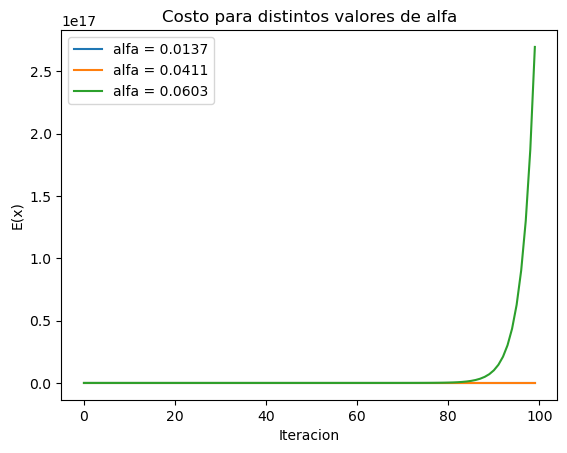

In [4]:
#c

X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
x_fantoma = X_fantoma.reshape(-1)

def mascara_rayo(n, direccion, s):
    res =  np.zeros((n, n))
    for i in range(n) :
        for j in range(n):
            if (direccion[0]*i + direccion[1]*j) == s:
                res[i,j] =1
    return res

def matriz_proyeccion(n, direcciones):
    filas_A = []
    for direccion in direcciones:
        valoresdes=[]
        for i in range(n):
            for j in range(n):
                s = direccion[0]*i + direccion[1]*j
                valoresdes.append(s)
    
        ssinrepetir = []

        for k in valoresdes:
            if k not in ssinrepetir:
                ssinrepetir.append(k)        

        ssinrepetir.sort()

        for s in ssinrepetir:
            fila_s =mascara_rayo(n, direccion, s)
            filas_A.append(fila_s.reshape(-1))
           
    A=np.array(filas_A)
    return A

d7 = [(1,0), (0,1), (1,1), (1, -1), (2,1),(1,2),(3,1)]

A7= matriz_proyeccion(8, d7)


def generar_mediciones(A, x):
    return A @ x

b7 = generar_mediciones(A7, x_fantoma)   

np.random.seed(42)
z = np.random.randn(len(b7))
escala = np.sqrt(np.mean(b7**2))

sigma = 0.06
eta = sigma * escala * z
b_sigma = b7 + eta

H = A7.T @ A7

def E(x):
     return (1/2 * (np.linalg.norm(A7@ x - b_sigma))**2)
    

def gradE(x):
    return A7.T@(A7@x - b_sigma )

autovalores = np.linalg.eigvalsh(H)
mu_max = np.max(autovalores)

limite = 2/ mu_max

alfas= [
    limite * 0.25,
    limite* 0.75,
    limite* 1.10
]



for alfa in alfas:
    x= np.zeros(64)
    costos = []

    for t in range(100):
        costos.append(E(x))

        grad = gradE(x)

        x= x - alfa*grad
        
    plt.plot(costos, label=f"alfa = {alfa:.4f}")

plt.title("Costo para distintos valores de alfa")
plt.xlabel("Iteracion")
plt.ylabel("E(x)")
plt.legend()
plt.show()

c)
Para valores de alfa dentro del intervalo 0 < alfa < 2/mu_max, el costo disminuye y el método converge. En cambio, cuando alfa supera ese límite, el costo aumenta fuertemente y el método se vuelve inestable. Esto se observa en la curva correspondiente al valor de alfa más grande.

In [6]:
#d)

H = A7.T @ A7

x0 = np.zeros(64)

grad = gradE(x0)

p = np.linalg.solve(H, grad)

x_newton = x0 - p

print("Costo inicial:", E(x0))
print("Costo despues de Newton:", E(x_newton))

x_lstsq = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]

print(
    "Diferencia Newton vs lstsq:",
    np.linalg.norm(x_newton - x_lstsq)
)


Costo inicial: 70.68760122588972
Costo despues de Newton: 0.08410238184800665
Diferencia Newton vs lstsq: 9.528526590510078e-15


In [10]:
#e)
x_lstsq = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]

print("GD vs Newton:",
      np.linalg.norm(x_gd - x_newton))

print("GD vs lstsq:",
      np.linalg.norm(x_gd - x_lstsq))

print("Newton vs lstsq:",
      np.linalg.norm(x_newton - x_lstsq))

GD vs Newton: 0.02331783236589273
GD vs lstsq: 0.023317832365892455
Newton vs lstsq: 9.528526590510078e-15


e)
Los tres métodos llegan prácticamente a la misma reconstrucción. Gradiente descendiente necesita varias iteraciones y requiere elegir una tasa de aprendizaje alfa adecuada. Newton llega en una sola iteración porque la función es cuadrática y su Hessiana es constante, aunque necesita resolver un sistema con la Hessiana. lstsq obtiene directamente la solución de mínimos cuadrados sin elegir una tasa de aprendizaje ni realizar iteraciones manuales.
